<a href="https://colab.research.google.com/github/ananyamatta1112-crypto/Optical-Polarimetry/blob/main/Polarimetry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install photutils

import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
import photutils

In [ ]:
!pip install rawpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 21.8 MB/s eta 0:00:00


In [ ]:
import rawpy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive


 0e18a739-71fb-40ac-9e3e-9e8f7402e489.mp4
 72adc305-48e1-4d49-90a6-1c045e768962.jpeg
'Advanced Michelson Interferometry'
'Ananya Matta EXP1'
'Ananya Matta EXP2'
'Ananya Matta EXP3'
 CGPA2.pdf
 Classroom
'Colab Notebooks'
'College '
'Copy of DSC_0417.NEF'
 DSC_0419.NEF
 DSC_0419.NEF.pdf
 group1lock.txt
 group1sweep.txt
'Lecture + Exp Photos '
'LIMB DARKENING '
'Mukta Matta Income Computation.pdf'
'Mukta Matta ITR Acknowledgement.pdf'
 Polarimetry
 Sam_ID.jpeg
'Saved from Chrome'


In [ ]:
!ls /content/drive/MyDrive/Polarimetry


'GROUP 1 EXPERIMENT DATED 05 FEB 2026'	 GROUP_1_POLARIMETRY.zip   __MACOSX


In [ ]:
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"


 OBSERVATIONS  'PROGRAM CODE'


In [ ]:
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"/OBSERVATIONS

'CYCLE 1'  'CYCLE 3'  'CYCLE 5'   Untitled13.FIT   Untitled16.FIT
'CYCLE 2'  'CYCLE 4'  'CYCLE 6'   Untitled15.FIT


In [ ]:
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"/OBSERVATIONS/"CYCLE 1"
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"/OBSERVATIONS/"CYCLE 2"
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"/OBSERVATIONS/"CYCLE 3"
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"/OBSERVATIONS/"CYCLE 4"
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"/OBSERVATIONS/"CYCLE 5"
!ls /content/drive/MyDrive/Polarimetry/"GROUP 1 EXPERIMENT DATED 05 FEB 2026"/OBSERVATIONS/"CYCLE 6"

with_HWP_0.FIT	with_HWP_22_5.FIT  with_HWP_45.FIT  with_HWP_67_5.FIT
with_HWP_0.FIT	with_HWP_22_5.FIT  with_HWP_45.FIT  with_HWP_67_5.FIT
Untitled29.FIT	with_HWP_22_5.FIT  with_HWP_67_5.FIT
with_HWP_0.FIT	with_HWP_45.FIT
wihout_HWP_0.FIT  without_HWP_45.FIT  without_HWP_90.FIT
without_HWP_0.FIT  without_HWP_45.FIT  without_HWP_90.FIT
without_HWP_0.FIT  without_HWP_45.FIT  without_HWP_90.FIT


Angle 0° stacked from 3 images
Angle 45° stacked from 3 images
Angle 90° stacked from 3 images
Angle 135° stacked from 3 images


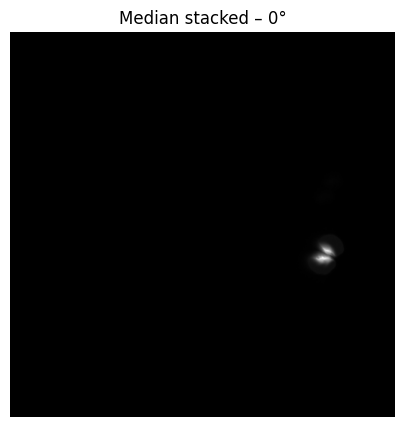

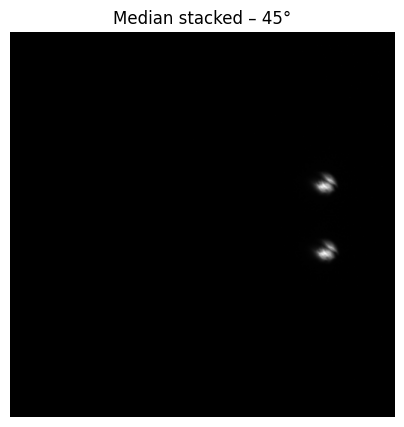

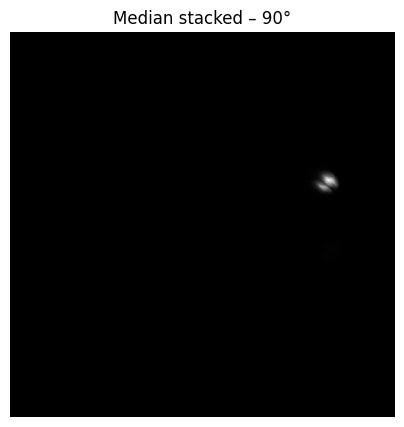

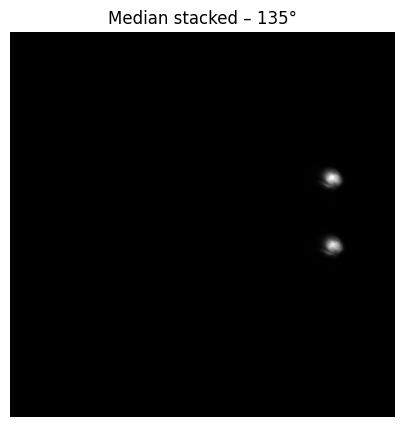

In [ ]:
from astropy.io import fits
import numpy as np
import os
import matplotlib.pyplot as plt

base_path = "/content/drive/MyDrive/Polarimetry/GROUP 1 EXPERIMENT DATED 05 FEB 2026/OBSERVATIONS"

cycles = ["CYCLE 1", "CYCLE 2", "CYCLE 3"]

angles = {
    "0": "with_HWP_0.FIT",
    "45": "with_HWP_22_5.FIT",
    "90": "with_HWP_45.FIT",
    "135": "with_HWP_67_5.FIT"
}

stacked_images = {}

for angle, fname in angles.items():
    imgs = []

    for cycle in cycles:
        path = os.path.join(base_path, cycle, fname)
        imgs.append(fits.getdata(path).astype(float))

    imgs = np.array(imgs)
    stacked_images[angle] = np.nanmedian(imgs, axis=0)

    print(f"Angle {angle}° stacked from {len(imgs)} images")

for angle, img in stacked_images.items():
    plt.figure(figsize=(5,5))
    plt.imshow(img, origin="lower", cmap="gray")
    plt.title(f"Median stacked – {angle}°")
    plt.axis("off")
    plt.show()


0° | sigma = 4.67 px | FWHM = 11.01 px


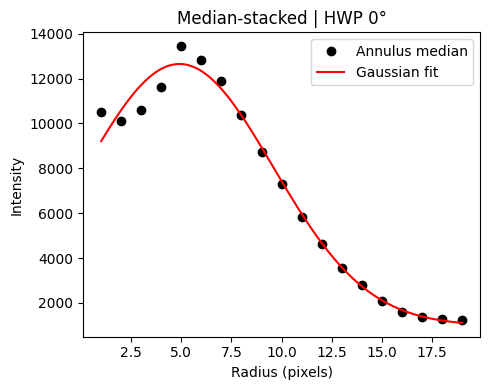

45° | sigma = 6.21 px | FWHM = 14.63 px


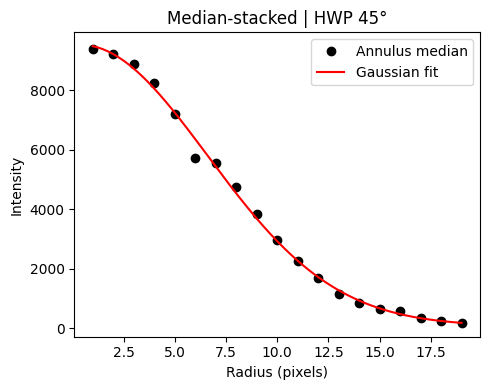

90° | sigma = 6.92 px | FWHM = 16.30 px


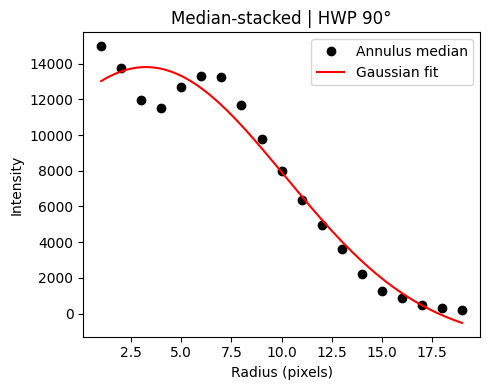

135° | sigma = 6.15 px | FWHM = 14.48 px


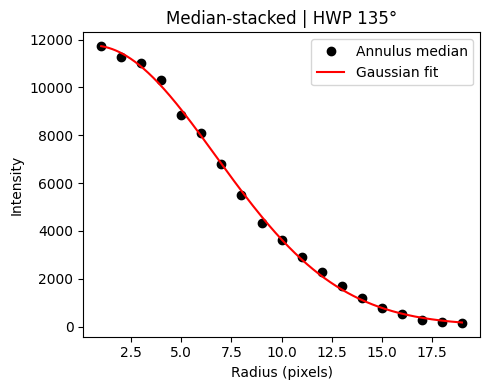

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import label, center_of_mass
from scipy.optimize import curve_fit
import os

base_path = "/content/drive/MyDrive/Polarimetry/GROUP 1 EXPERIMENT DATED 05 FEB 2026/OBSERVATIONS"

cycles = ["CYCLE 1", "CYCLE 2", "CYCLE 3"]

angles = {
    "0°": "with_HWP_0.FIT",
    "45°": "with_HWP_22_5.FIT",
    "90°": "with_HWP_45.FIT",
    "135°": "with_HWP_67_5.FIT"
}

def gaussian_1d(r, amp, r0, sigma, offset):
    return offset + amp * np.exp(-(r - r0)**2 / (2 * sigma**2))

r_min = 1
r_max = 20
dr = 1
radii = np.arange(r_min, r_max, dr)

for angle, fname in angles.items():

    images = []

    for cycle in cycles:
        path = os.path.join(base_path, cycle, fname)
        images.append(fits.getdata(path).astype(float))

    stack = np.nanmedian(np.array(images), axis=0)

    thresh = np.nanmean(stack) + 5*np.nanstd(stack)
    labels, nsrc = label(stack > thresh)

    if nsrc == 0:
        print(f"No source detected for {angle}")
        continue

    yc, xc = center_of_mass(stack, labels, 1)
    yc, xc = int(yc), int(xc)

    y, x = np.indices(stack.shape)
    radial_I = []

    for r in radii:
        mask = ((x-xc)**2 + (y-yc)**2 >= r**2) & \
               ((x-xc)**2 + (y-yc)**2 < (r+dr)**2)

        if np.sum(mask) == 0:
            radial_I.append(np.nan)
        else:
            radial_I.append(np.nanmedian(stack[mask]))

    radial_I = np.array(radial_I)
    valid = ~np.isnan(radial_I)

    r_fit = radii[valid]
    I_fit = radial_I[valid]

    p0 = [I_fit.max(), 0, 3, np.median(I_fit)]
    popt, _ = curve_fit(gaussian_1d, r_fit, I_fit, p0=p0)

    amp, r0, sigma, offset = popt
    FWHM = 2.355 * sigma

    print(f"{angle} | sigma = {sigma:.2f} px | FWHM = {FWHM:.2f} px")

    r_fine = np.linspace(r_fit.min(), r_fit.max(), 500)

    plt.figure(figsize=(5,4))
    plt.plot(r_fit, I_fit, 'ko', label="Annulus median")
    plt.plot(r_fine, gaussian_1d(r_fine, *popt), 'r-', label="Gaussian fit")
    plt.xlabel("Radius (pixels)")
    plt.ylabel("Intensity")
    plt.title(f"Median-stacked | HWP {angle}")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np
import pandas as pd

I0   = df[df["Angle"] == "0°"]["I_peak"].values[0]
I45  = df[df["Angle"] == "45°"]["I_peak"].values[0]
I90  = df[df["Angle"] == "90°"]["I_peak"].values[0]
I135 = df[df["Angle"] == "135°"]["I_peak"].values[0]

I = (I0 + I45 + I90 + I135) / 2.0
Q = I0 - I90
U = I45 - I135

P = np.sqrt(Q**2 + U**2) / I
theta = 0.5 * np.degrees(np.arctan2(U, Q))

print("Stokes parameters:")
print(f"I = {I:.3f}")
print(f"Q = {Q:.3f}")
print(f"U = {U:.3f}")

print("\nPolarization:")
print(f"Degree of polarization P = {P:.4f}")
print(f"Polarization angle θ = {theta:.2f} degrees")


Stokes parameters:
I = 23869.332
Q = -1151.867
U = -2231.194

Polarization:
Degree of polarization P = 0.1052
Polarization angle θ = -58.65 degrees


CYCLE 1 | 0° | FWHM = 14.80 px


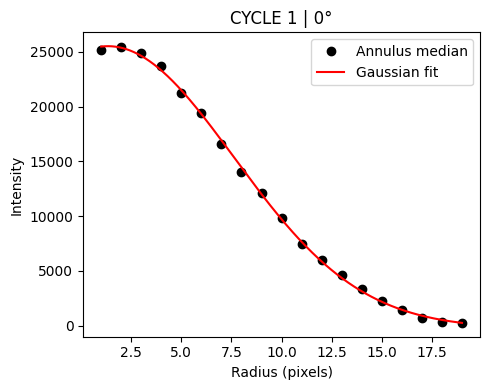

CYCLE 1 | 45° | FWHM = 14.13 px


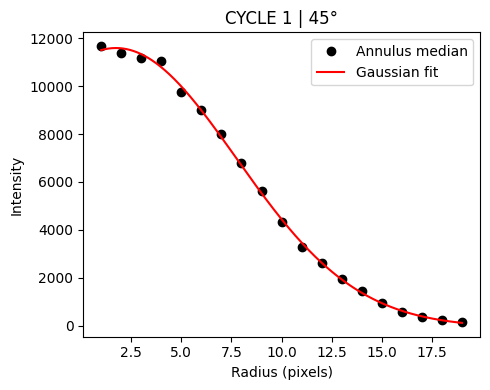

CYCLE 1 | 45° | FWHM = 14.33 px


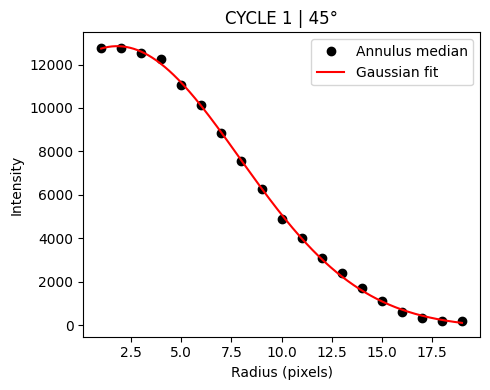

CYCLE 1 | 90° | FWHM = 14.99 px


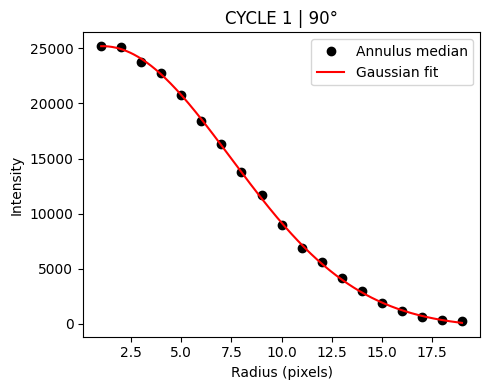

CYCLE 1 | 135° | FWHM = 15.25 px


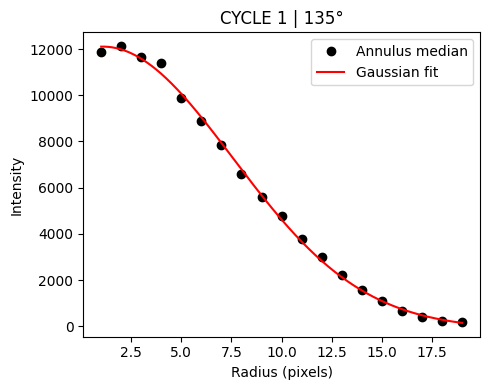

CYCLE 1 | 135° | FWHM = 15.30 px


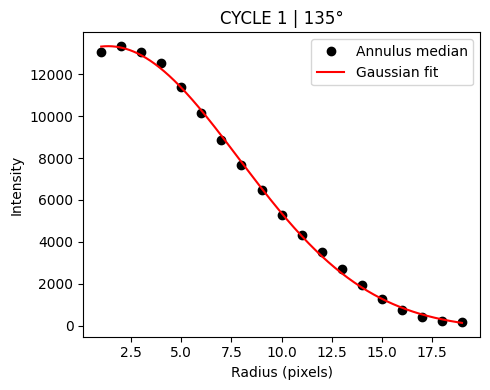

CYCLE 2 | 0° | FWHM = 14.88 px


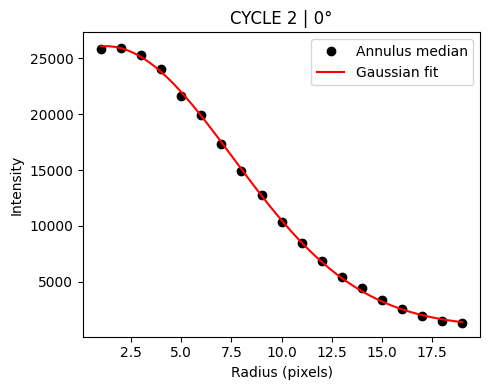

CYCLE 2 | 45° | FWHM = 13.02 px


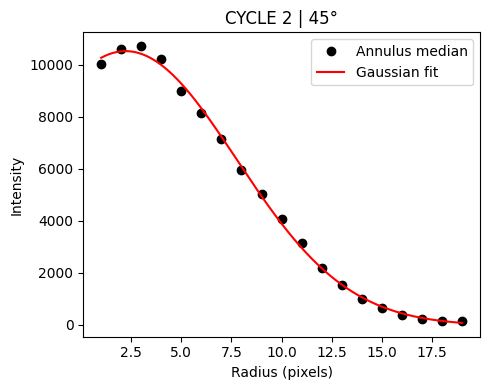

CYCLE 2 | 45° | FWHM = 12.50 px


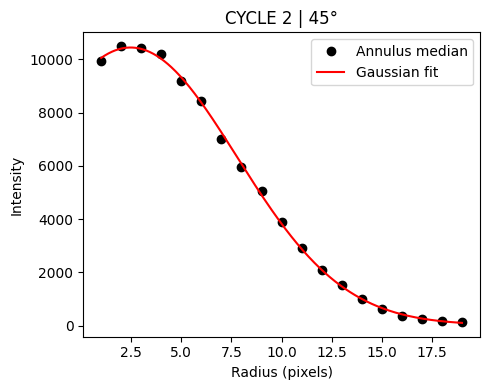

CYCLE 2 | 90° | FWHM = 15.04 px


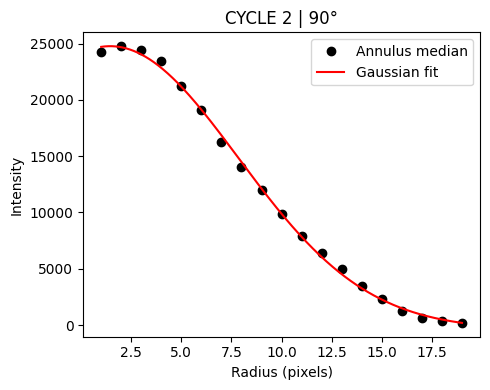

CYCLE 2 | 135° | FWHM = 14.31 px


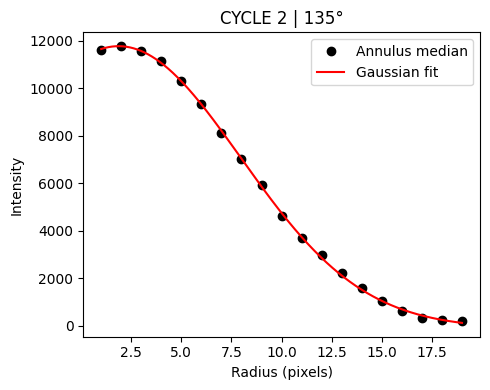

CYCLE 2 | 135° | FWHM = 14.34 px


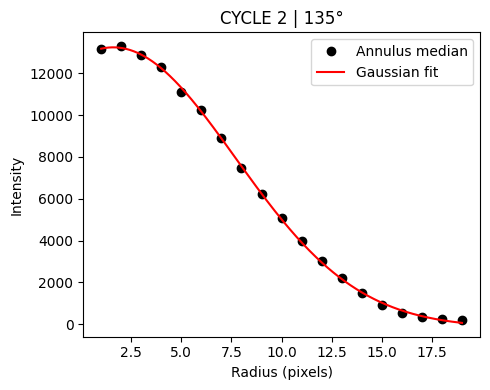

CYCLE 3 | 0° | FWHM = 14.37 px


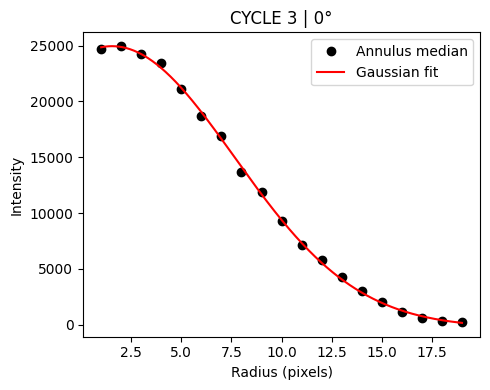

CYCLE 3 | 45° | FWHM = 14.45 px


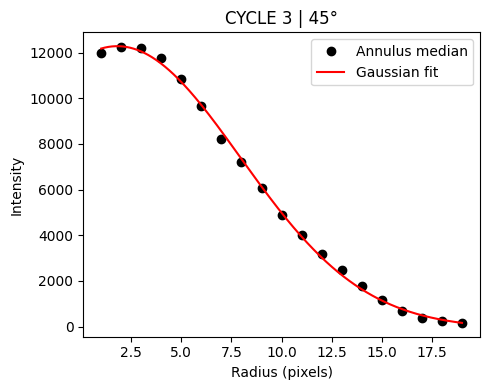

CYCLE 3 | 45° | FWHM = 14.54 px


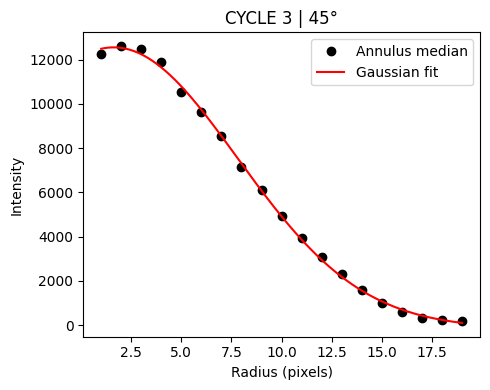

CYCLE 3 | 90° | FWHM = 14.75 px


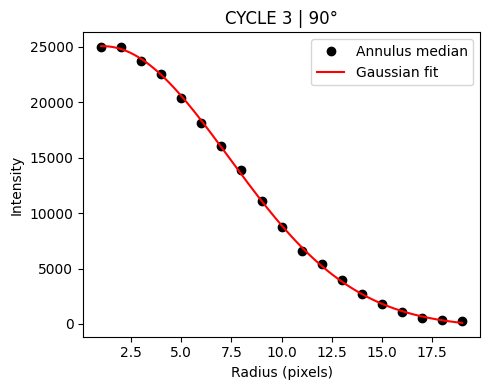

CYCLE 3 | 135° | FWHM = 14.61 px


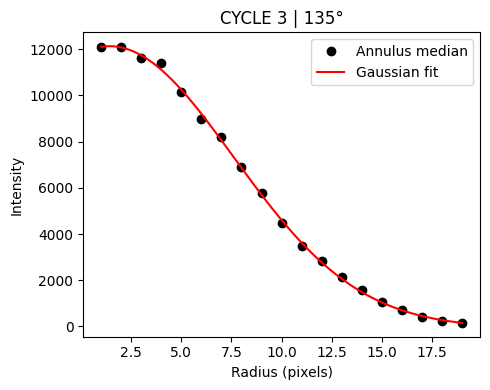

CYCLE 3 | 135° | FWHM = 14.77 px


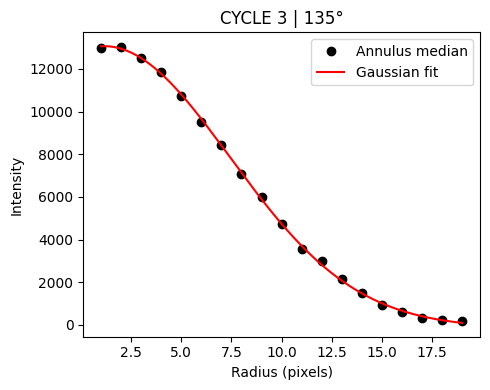

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import label, center_of_mass
from scipy.optimize import curve_fit
import os

base_path = "/content/drive/MyDrive/Polarimetry/GROUP 1 EXPERIMENT DATED 05 FEB 2026/OBSERVATIONS"

cycles = ["CYCLE 1", "CYCLE 2", "CYCLE 3"]

angles = {
    "0°": "with_HWP_0.FIT",
    "45°": "with_HWP_22_5.FIT",
    "90°": "with_HWP_45.FIT",
    "135°": "with_HWP_67_5.FIT"
}

r_min = 1
r_max = 20
dr = 1
radii = np.arange(r_min, r_max, dr)

def gaussian_1d(r, amp, r0, sigma, offset):
    return offset + amp * np.exp(-(r - r0)**2 / (2 * sigma**2))

for cycle in cycles:
    for angle, fname in angles.items():

        path = os.path.join(base_path, cycle, fname)
        image = fits.getdata(path).astype(float)

        thresh = np.nanmean(image) + 5*np.nanstd(image)
        labels, nsrc = label(image > thresh)
        centroids = center_of_mass(image, labels, range(1, nsrc + 1))

        if nsrc == 0:
            continue

        for (yc, xc) in centroids:

            yc, xc = int(yc), int(xc)

            radial_intensity = []

            for r in radii:
                y, x = np.indices(image.shape)
                mask = ((x-xc)**2 + (y-yc)**2 >= r**2) & \
                       ((x-xc)**2 + (y-yc)**2 < (r+dr)**2)

                if np.sum(mask) == 0:
                    radial_intensity.append(np.nan)
                else:
                    radial_intensity.append(np.nanmedian(image[mask]))

            radial_intensity = np.array(radial_intensity)

            valid = ~np.isnan(radial_intensity)
            r_fit = radii[valid]
            I_fit = radial_intensity[valid]

            p0 = [I_fit.max(), 0, 3, np.median(I_fit)]
            popt, _ = curve_fit(gaussian_1d, r_fit, I_fit, p0=p0)

            amp, r0, sigma, offset = popt
            FWHM = 2.355 * sigma

            print(f"{cycle} | {angle} | FWHM = {FWHM:.2f} px")

            r_fine = np.linspace(r_fit.min(), r_fit.max(), 500)

            plt.figure(figsize=(5,4))
            plt.plot(r_fit, I_fit, 'ko', label="Annulus median")
            plt.plot(r_fine, gaussian_1d(r_fine, *popt), 'r-', label="Gaussian fit")
            plt.xlabel("Radius (pixels)")
            plt.ylabel("Intensity")
            plt.title(f"{cycle} | {angle}")
            plt.legend()
            plt.tight_layout()
            plt.show()
